In [1]:
# Setup & Imports
!pip install -q PySastrawi
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
sns.set_theme(style="darkgrid")

Phase 2: Data Preparation & Labeling

In [2]:
# [CELL 2] Data Loading and Label Mapping
raw_df = pd.read_csv('dataset/data.csv', encoding='latin-1')

# Mapping labels using numpy select for better efficiency
conditions = [
    (raw_df['HS'] == 1),
    (raw_df['Abusive'] == 1) & (raw_df['HS'] == 0)
]
class_choices = ['Hate Speech', 'Abusive']
raw_df['Category'] = np.select(conditions, class_choices, default='Neutral')

print("Dataset Information:")
print(raw_df['Category'].value_counts())
display(raw_df[['Tweet', 'Category']].head())

Dataset Information:
Category
Neutral        5860
Hate Speech    5561
Abusive        1748
Name: count, dtype: int64


,Tweet,Category
0,- disaat semua cowok berusaha melacak perhatia...,Hate Speech
1,RT USER: USER siapa yang telat ngasih tau elu?...,Abusive
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",Neutral
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,Neutral
4,USER USER Kaum cebong kapir udah keliatan dong...,Hate Speech


Phase 3: Text Preprocessing Pipeline

In [3]:
# Load External Dictionaries for mapping
slang_data = pd.read_csv('dataset/new_kamusalay.csv', encoding='latin-1', header=None)
slang_dict = pd.Series(slang_data[1].values, index=slang_data[0]).to_dict()

id_stopwords = set(stopwords.words('indonesian'))
# PERBAIKAN DI SINI: menggunakan create_stemmer()
id_stemmer = StemmerFactory().create_stemmer()

# Consolidated Text Preprocessing Function
def text_cleaner(sentence):
    text = str(sentence).lower()
    text = re.sub(r'\\x[a-f0-9]{2}', ' ', text)
    text = re.sub(r'\b(rt|user|url)\b', ' ', text)
    text = re.sub(r'[^a-z]+', ' ', text).strip()
    
    words = text.split()
    final_tokens = []
    
    for word in words:
        formal_word = slang_dict.get(word, word)
        if formal_word not in id_stopwords:
            stemmed_word = id_stemmer.stem(formal_word)
            if stemmed_word: 
                final_tokens.append(stemmed_word)
                
    return ' '.join(final_tokens)

print("Text cleaning process is running... (This might take a while)")
raw_df['Clean_Text'] = raw_df['Tweet'].apply(text_cleaner)
display(raw_df[['Tweet', 'Clean_Text']].sample(5))

Text cleaning process is running... (This might take a while)


,Tweet,Clean_Text
4247,USER USER USER USER USER USER USER USER USER U...,teruk ya
1242,RT USER: Pe Ka eS lagiiiii...!!! USER gitu lho...,pe kakak es lagiiiii lo partai kampret sejati
7975,(((Kelompok))) bang,kelompok bang
710,USER Lah lu bom apa gimana?jauh jauh dah gua n...,bom gue nih takut
6047,Nah junjungan kita nabi agung Muhammad Saw aja...,junjung nabi agung muhammad saw ajar orang isl...


Phase 4: Feature Extraction & Data Splitting (80:20)

In [4]:
# [CELL 5] Splitting Data
X_features = raw_df['Clean_Text']
y_target = raw_df['Category']

# Split Data: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_target, test_size=0.20, random_state=42, stratify=y_target
)

print(f"Training Samples : {X_train.shape[0]}")
print(f"Testing Samples  : {X_test.shape[0]}")

# Vectorizer akan di-fit di dalam Pipeline pada setiap fold cross-validation.
# Hal ini mencegah informasi dari validation fold bocor ke vocabulary/IDF.

Training Samples : 10535
Testing Samples  : 2634


Phase 5: Model Training Pipeline

In [5]:
# Pengaturan bersama untuk tuning keempat model
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_collection = {}
best_parameters = {}
evaluation_metrics = {}
model_predictions = {}

def record_result(algo_name, search):
    # Simpan model terbaik dan ukur performanya pada test set.
    best_pipeline = search.best_estimator_
    model_collection[algo_name] = best_pipeline.named_steps['model']
    best_parameters[algo_name] = search.best_params_

    preds = best_pipeline.predict(X_test)
    model_predictions[algo_name] = preds
    report = classification_report(y_test, preds, output_dict=True, zero_division=0)
    evaluation_metrics[algo_name] = {
        'CV_Macro_F1': search.best_score_,
        'Accuracy': accuracy_score(y_test, preds),
        'Macro_Precision': report['macro avg']['precision'],
        'Recall_HS': report['Hate Speech']['recall'],
        'Macro_F1': report['macro avg']['f1-score']
    }
    print(f'{algo_name} best parameters: {search.best_params_}')
    print(f'Best CV Macro F1: {search.best_score_:.4f}')

In [6]:
# 1. Naive Bayes + CountVectorizer
nb_pipeline = Pipeline([
    ('vectorizer', CountVectorizer(ngram_range=(1, 2))),
    ('model', MultinomialNB())
])
nb_search = GridSearchCV(
    nb_pipeline, {'model__alpha': [0.1, 0.5, 1.0, 2.0]},
    scoring='f1_macro', cv=cv_strategy, n_jobs=-1, refit=True, verbose=1
)
nb_search.fit(X_train, y_train)
count_vec = nb_search.best_estimator_.named_steps['vectorizer']
record_result('Naive Bayes', nb_search)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Naive Bayes best parameters: {'model__alpha': 0.1}
Best CV Macro F1: 0.7483


In [7]:
# 2. KNN + TF-IDF
knn_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ('model', KNeighborsClassifier(algorithm='brute'))
])
knn_params = {
    'model__n_neighbors': [3, 5, 7, 11],
    'model__metric': ['cosine', 'euclidean']
}
knn_search = GridSearchCV(
    knn_pipeline, knn_params,
    scoring='f1_macro', cv=cv_strategy, n_jobs=-1, refit=True, verbose=1
)
knn_search.fit(X_train, y_train)
record_result('K-NN', knn_search)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
K-NN best parameters: {'model__metric': 'cosine', 'model__n_neighbors': 11}
Best CV Macro F1: 0.6967


In [8]:
# 3. Logistic Regression + TF-IDF
logreg_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=2000, random_state=42))
])
logreg_params = {
    'model__C': [0.1, 1.0, 10.0],
    'model__class_weight': [None, 'balanced']
}
logreg_search = GridSearchCV(
    logreg_pipeline, logreg_params,
    scoring='f1_macro', cv=cv_strategy, n_jobs=-1, refit=True, verbose=1
)
logreg_search.fit(X_train, y_train)
record_result('LogReg', logreg_search)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
LogReg best parameters: {'model__C': 10.0, 'model__class_weight': None}
Best CV Macro F1: 0.7845


In [9]:
# 4. Linear SVM + TF-IDF
svm_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ('model', SVC(kernel='linear', random_state=42))
])
svm_params = {
    'model__C': [0.1, 0.5, 1.0, 2.0, 5.0],
    'model__class_weight': [None, 'balanced']
}
svm_search = GridSearchCV(
    svm_pipeline, svm_params,
    scoring='f1_macro', cv=cv_strategy, n_jobs=-1, refit=True, verbose=1
)
svm_search.fit(X_train, y_train)
tfidf_vec = svm_search.best_estimator_.named_steps['vectorizer']
record_result('SVM (Linear)', svm_search)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
SVM (Linear) best parameters: {'model__C': 2.0, 'model__class_weight': 'balanced'}
Best CV Macro F1: 0.7864


Phase 6: Performance Evaluation & Visualizations

In [10]:
# [CELL 9] Display Performance Comparison Table

performance_df = pd.DataFrame.from_dict(evaluation_metrics, orient='index')

final_table = performance_df[['CV_Macro_F1', 'Accuracy', 'Macro_Precision', 'Recall_HS', 'Macro_F1']].rename(
    columns={
        'CV_Macro_F1': 'CV F1-Macro',
        'Macro_Precision': 'Macro Precision', 
        'Recall_HS': 'Hate Speech Recall', 
        'Macro_F1': 'Test F1-Macro'
    }
)

print('Best hyperparameters:')
for algorithm, params in best_parameters.items():
    print(f'{algorithm}: {params}')

display(final_table.style.format("{:.4f}").background_gradient(cmap='YlGnBu'))

Best hyperparameters:
Naive Bayes: {'model__alpha': 0.1}
K-NN: {'model__metric': 'cosine', 'model__n_neighbors': 11}
LogReg: {'model__C': 10.0, 'model__class_weight': None}
SVM (Linear): {'model__C': 2.0, 'model__class_weight': 'balanced'}


,CV F1-Macro,Accuracy,Macro Precision,Hate Speech Recall,Test F1-Macro
Naive Bayes,0.7483,0.7809,0.7494,0.8129,0.7548
K-NN,0.6967,0.7369,0.7223,0.8085,0.7060
LogReg,0.7845,0.8193,0.7998,0.8273,0.7909
SVM (Linear),0.7864,0.8090,0.7765,0.8192,0.7787


In [11]:
import joblib
import os

# Buat folder 'models' jika belum ada
if not os.path.exists('models'):
    os.makedirs('models')

# Simpan Vectorizers
joblib.dump(count_vec, 'models/count_vec.pkl')
joblib.dump(tfidf_vec, 'models/tfidf_vec.pkl')

# Simpan model terbaik hasil tuning
joblib.dump(model_collection['Naive Bayes'], 'models/nb_model.pkl')
joblib.dump(model_collection['K-NN'], 'models/knn_model.pkl')
joblib.dump(model_collection['LogReg'], 'models/logreg_model.pkl')
joblib.dump(model_collection['SVM (Linear)'], 'models/svm_model.pkl')

print("Semua model dan vectorizer berhasil disimpan ke folder 'models'!")

Semua model dan vectorizer berhasil disimpan ke folder 'models'!


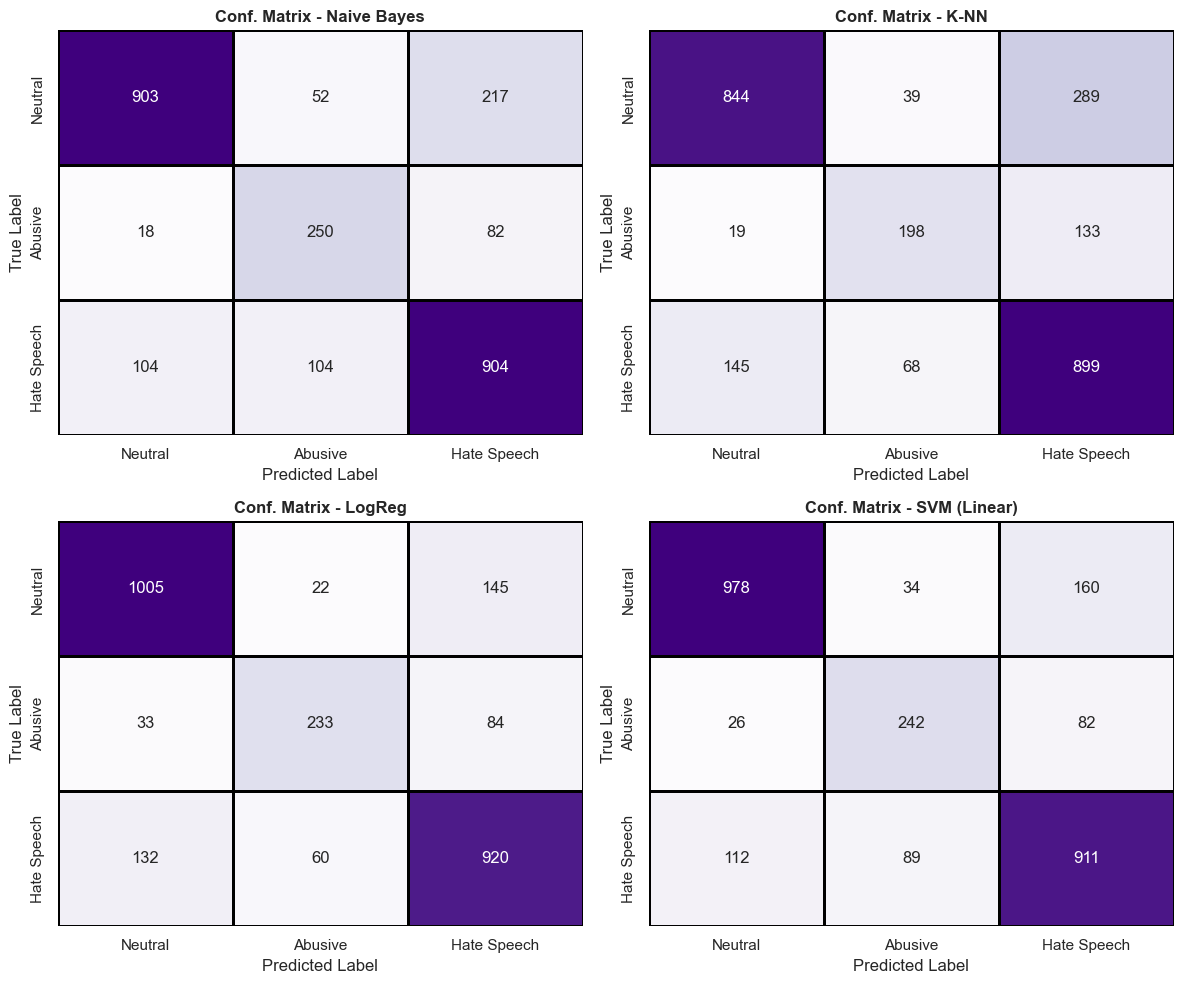

In [12]:
# [CELL 10] Confusion Matrix Visualizations
class_order = ['Neutral', 'Abusive', 'Hate Speech']

fig, ax = plt.subplots(2, 2, figsize=(12, 10))
ax = ax.flatten()

for i, (algo_name, preds) in enumerate(model_predictions.items()):
    cm = confusion_matrix(y_test, preds, labels=class_order)
    
    sns.heatmap(cm, annot=True, fmt='g', cmap='Purples', ax=ax[i], 
                xticklabels=class_order, yticklabels=class_order, 
                cbar=False, linewidths=1, linecolor='black')
    
    ax[i].set_title(f'Conf. Matrix - {algo_name}', fontweight='bold')
    ax[i].set_xlabel('Predicted Label')
    ax[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [13]:
print("====================================================")
print("  Interactive Hate Speech & Abusive Detection Loop  ")
print("====================================================\n")
print("Instructions:")
print("- Type any sentence/tweet to test the models.")
print("- Type 'exit' or 'quit' to stop the program.\n")

while True:
    user_input = input("Enter a sentence to test: ")
    
    if user_input.lower().strip() in ['exit', 'quit']:
        print("\nProgram terminated. Thank you!")
        break
        
    if not user_input.strip():
        continue
        
    print("\nProcessing text...")
    cleaned_input = text_cleaner(user_input)
    print(f"Cleaned Text   : '{cleaned_input}'")
    print("-" * 50)
    
    # Transformasi input ke format matriks
    input_vector_count = count_vec.transform([cleaned_input])
    input_vector_tfidf = tfidf_vec.transform([cleaned_input])
    
    print(f"{'Algorithm':<20} | {'Predicted Category'}")
    print("-" * 50)
    
    for algo_name, actual_model in model_collection.items():
            
        # Tentukan jenis vectorizer berdasarkan nama algoritmanya
        if algo_name == "Naive Bayes":
            prediction = actual_model.predict(input_vector_count)[0]
        else:
            prediction = actual_model.predict(input_vector_tfidf)[0]
            
        print(f"{algo_name:<20} | {prediction}")
        
    print("====================================================\n")

  Interactive Hate Speech & Abusive Detection Loop  

Instructions:
- Type any sentence/tweet to test the models.
- Type 'exit' or 'quit' to stop the program.


Program terminated. Thank you!
